# E1 · Resultados

Carga las métricas guardadas en `results/` y las figuras de `figures/`. No recalcula nada.

In [1]:
import json, pandas as pd
from pathlib import Path
from IPython.display import Image, display
R = Path('../results'); F = Path('../figures')
S = json.load(open(R / 'summary_main.json'))
pd.set_option('display.max_colwidth', 80)

## Tabla principal (test, n = 120; IC 95 % bootstrap)

In [2]:
pd.read_csv(R / 'main_table.csv').sort_values('dice_media')

,metodo,dice_media,ic95_lo,ic95_hi,prompts_humanos,parametros_entrenados
19,"Tokens aprendidos k=4 · init. aleatoria, pre-registrada (1 semilla)",0.0082,0.0024,0.0161,0,1024
0,Sin prompt · salida única (token 0),0.0122,0.0007,0.0277,0,0
10,AMG · elige mayor IoU predicho,0.0578,0.0362,0.0824,0,0
1,"Sin prompt · multimáscara, elige cabeza IoU",0.1259,0.0921,0.1634,0,0
2,Sin prompt · mejor de 4 salidas (oráculo),0.1573,0.1206,0.1975,0 (oráculo),0
12,AMG · elige la más central,0.2185,0.1784,0.2621,0,0
11,AMG · elige la mayor,0.2414,0.1974,0.2878,0,0
17,Tokens aprendidos k=1 · init. clic medio (3 semillas),0.2785,0.2100,0.3475,0,256
18,Tokens aprendidos k=4 · init. clic medio (3 semillas),0.3178,0.2534,0.3833,0,1024
20,Dos etapas: tokens k=4 → caja → SAM (3 semillas),0.3265,0.2587,0.3944,0,1024


## Teardown

In [3]:
t = S['teardown']
print('parámetros:', t['params'])
print('GFLOPs encoder: %.1f | global/ventana: %.2f' % (t['flops']['encoder_GFLOPs'], t['flops']['global_over_window_ratio']))
pd.DataFrame(t['flops']['blocks'])

parámetros: {'total': 93735472, 'image_encoder': 89670912, 'prompt_encoder': 6220, 'mask_decoder': 4058340}
GFLOPs encoder: 972.1 | global/ventana: 1.70


,block,type,GFLOPs,attn_matmul_GFLOPs,qkv_proj_GFLOPs,mlp_GFLOPs
0,0,window,64.936894,3.161088,23.121101,38.654706
1,1,window,64.936894,3.161088,23.121101,38.654706
2,2,global,110.326972,52.344914,19.327353,38.654706
3,3,window,64.936894,3.161088,23.121101,38.654706
4,4,window,64.936894,3.161088,23.121101,38.654706
5,5,global,110.326972,52.344914,19.327353,38.654706
6,6,window,64.936894,3.161088,23.121101,38.654706
7,7,window,64.936894,3.161088,23.121101,38.654706
8,8,global,110.326972,52.344914,19.327353,38.654706
9,9,window,64.936894,3.161088,23.121101,38.654706


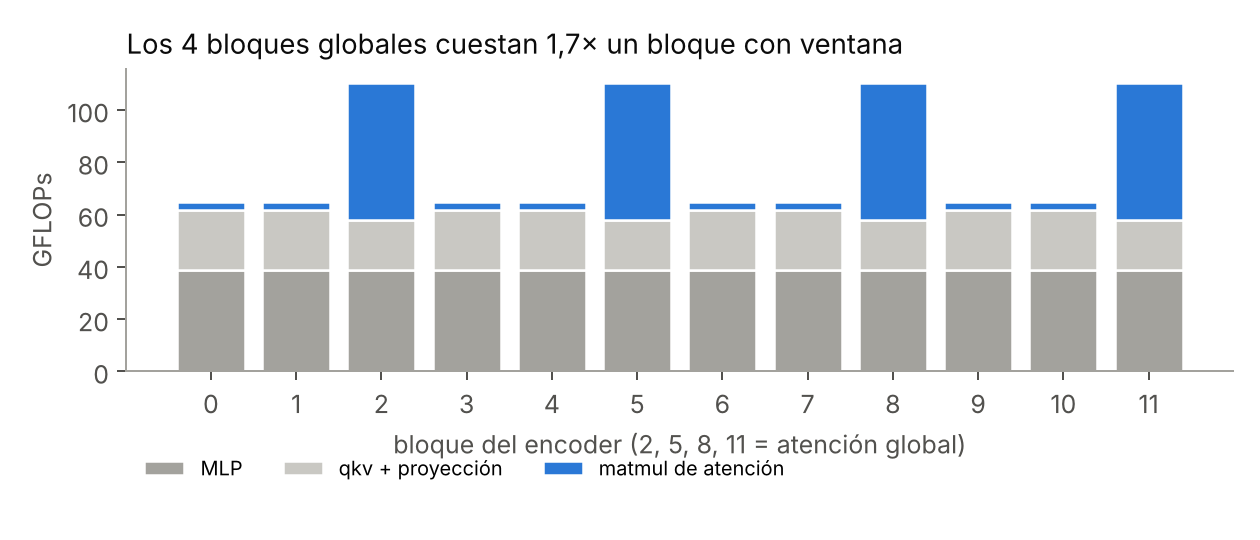

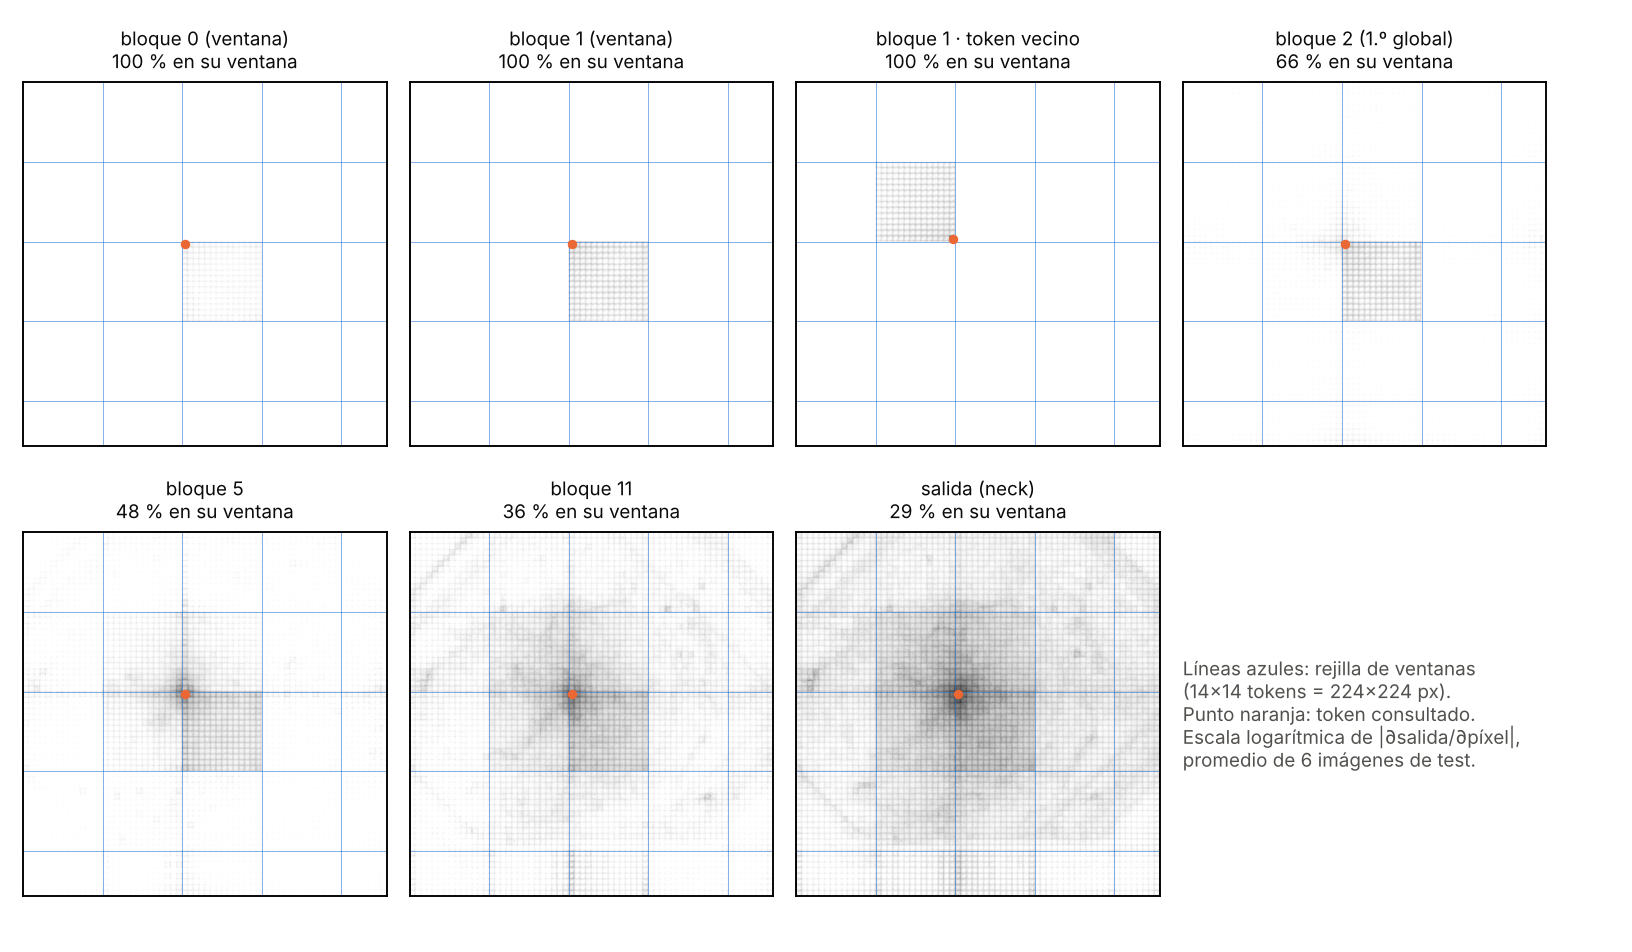

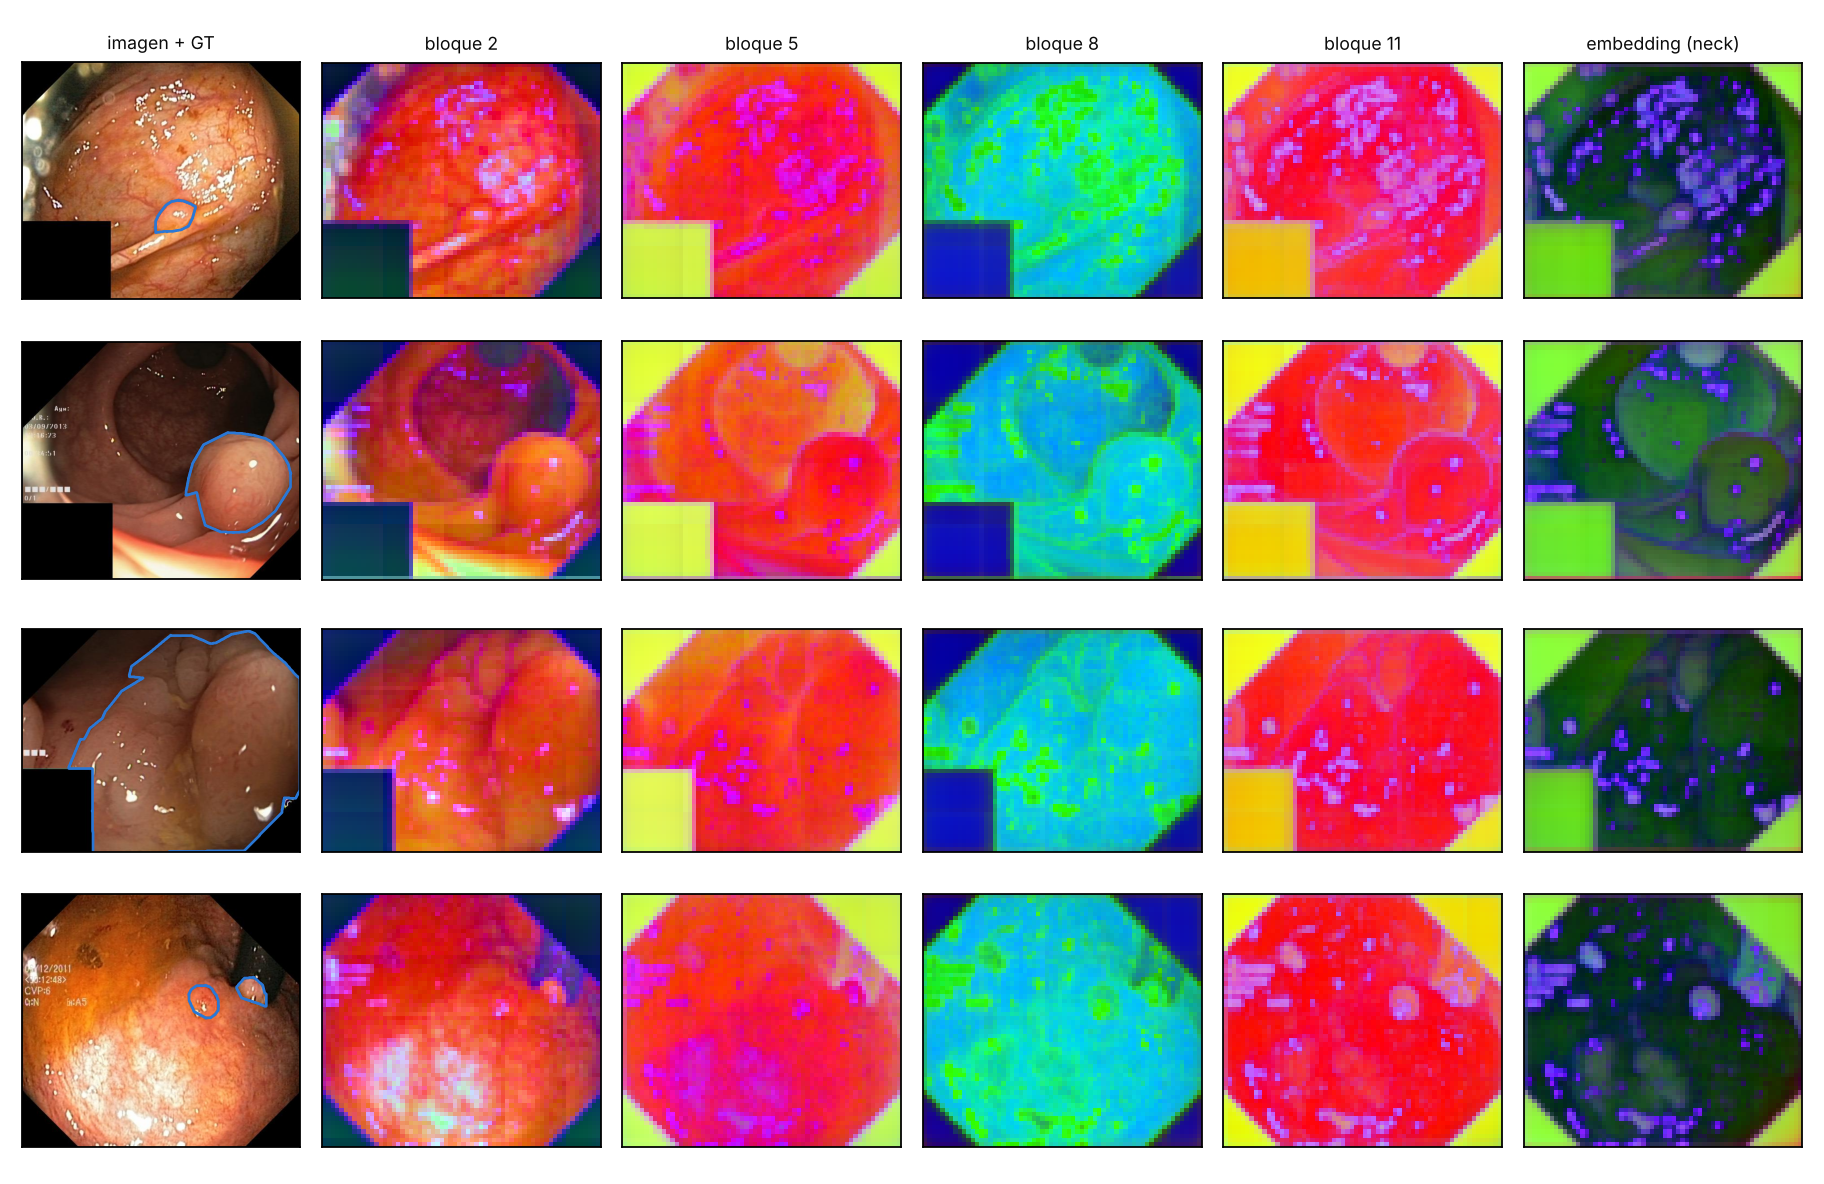

In [4]:
display(Image(F / 'teardown_flops_por_bloque.png', width=650))
display(Image(F / 'erf.png', width=650))
display(Image(F / 'pca_por_capa.png', width=650))

## Sin prompt, AMG y calibración

In [5]:
print(json.dumps(S.get('noprompt_tokens'), indent=1))
print(json.dumps(S.get('amg'), indent=1))
print(json.dumps(S.get('calibration'), indent=1))

{
 "t0": {
  "dice": 0.012184110026812137,
  "area": 0.01582039844330231,
  "border_frac": 0.11191987530030184,
  "pred_iou": 0.16466620638966561,
  "empty_rate": 0.7083333333333334
 },
 "t1": {
  "dice": 0.1282135531010054,
  "area": 0.5309358020275442,
  "border_frac": 0.19410399551289054,
  "pred_iou": 0.7358578423659007,
  "empty_rate": 0.016666666666666666
 },
 "t2": {
  "dice": 0.06859692963399974,
  "area": 0.2609452349414883,
  "border_frac": 0.23692219450164761,
  "pred_iou": 0.5928791227440039,
  "empty_rate": 0.016666666666666666
 },
 "t3": {
  "dice": 0.03575767133031496,
  "area": 0.01628749065378919,
  "border_frac": 0.23289643724126824,
  "pred_iou": 0.3649867410461108,
  "empty_rate": 0.15833333333333333
 }
}
{
 "n_raw": 768.0,
 "n_iou_filter": 458.65,
 "n_stab_filter": 156.01666666666668,
 "n_final": 15.383333333333333,
 "best_raw_pred_iou": 0.8289904880026976,
 "best_raw_stab": 0.6866086556352456,
 "best_raw_area": 0.1583883558671611,
 "frac_images_no_mask": 0.0,
 "fr

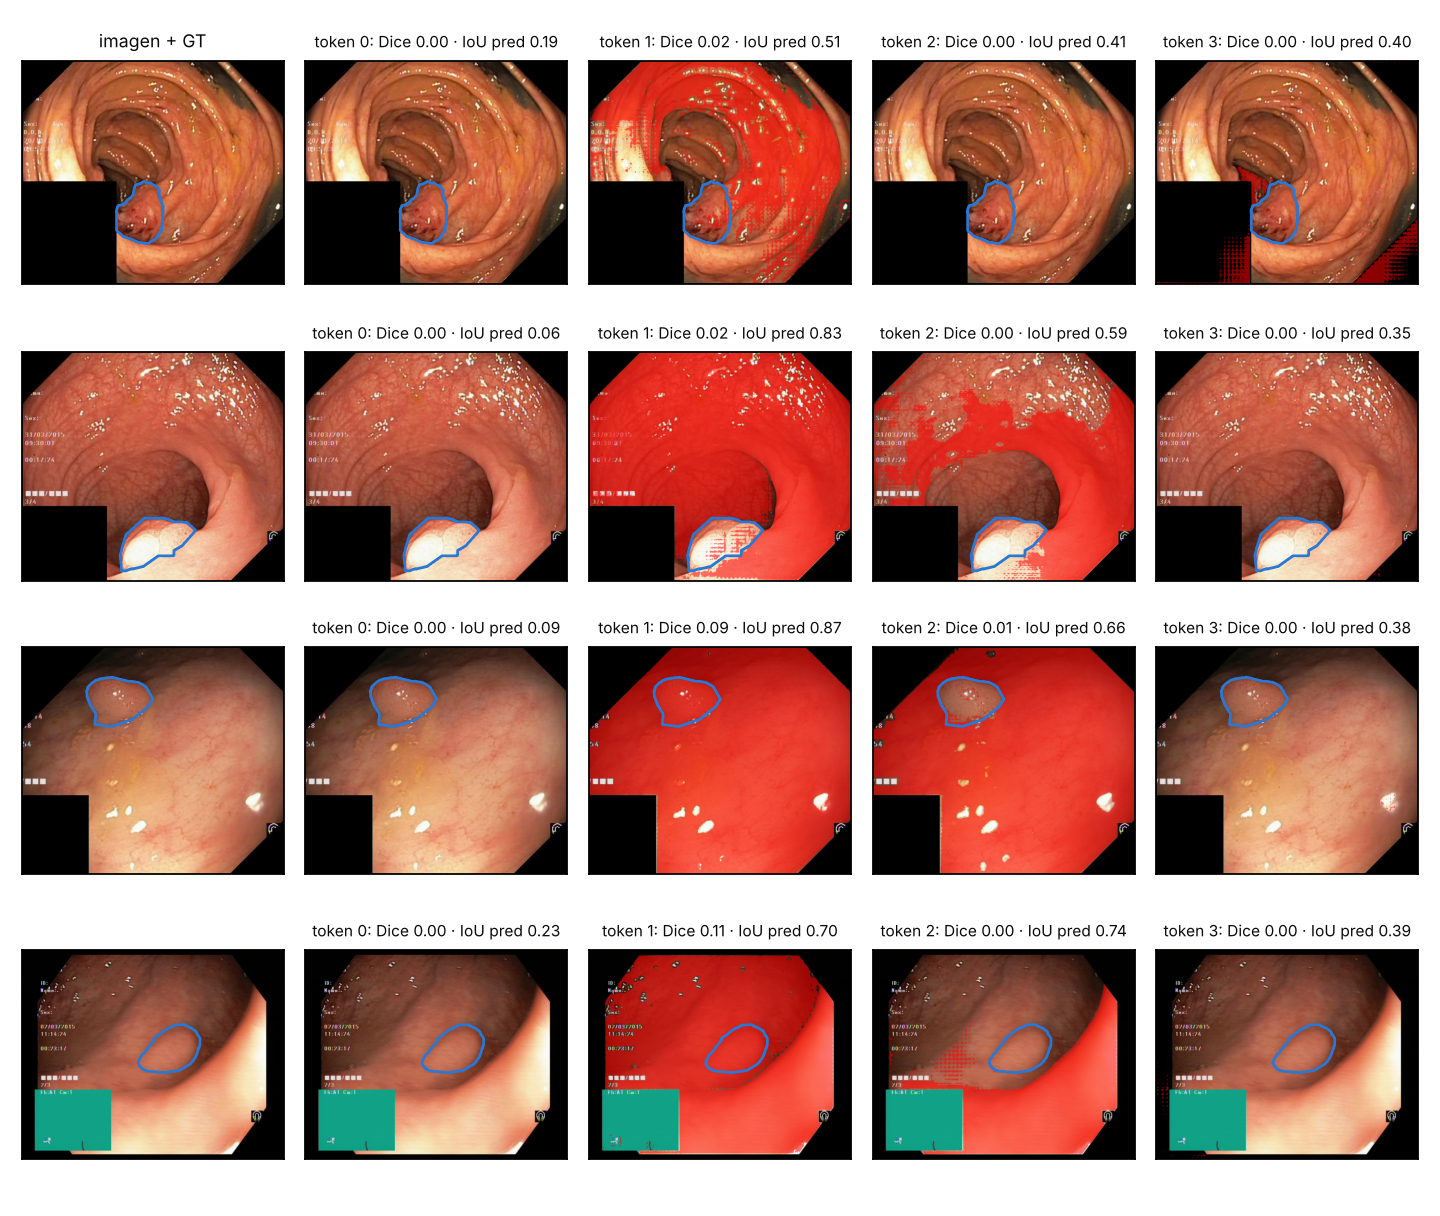

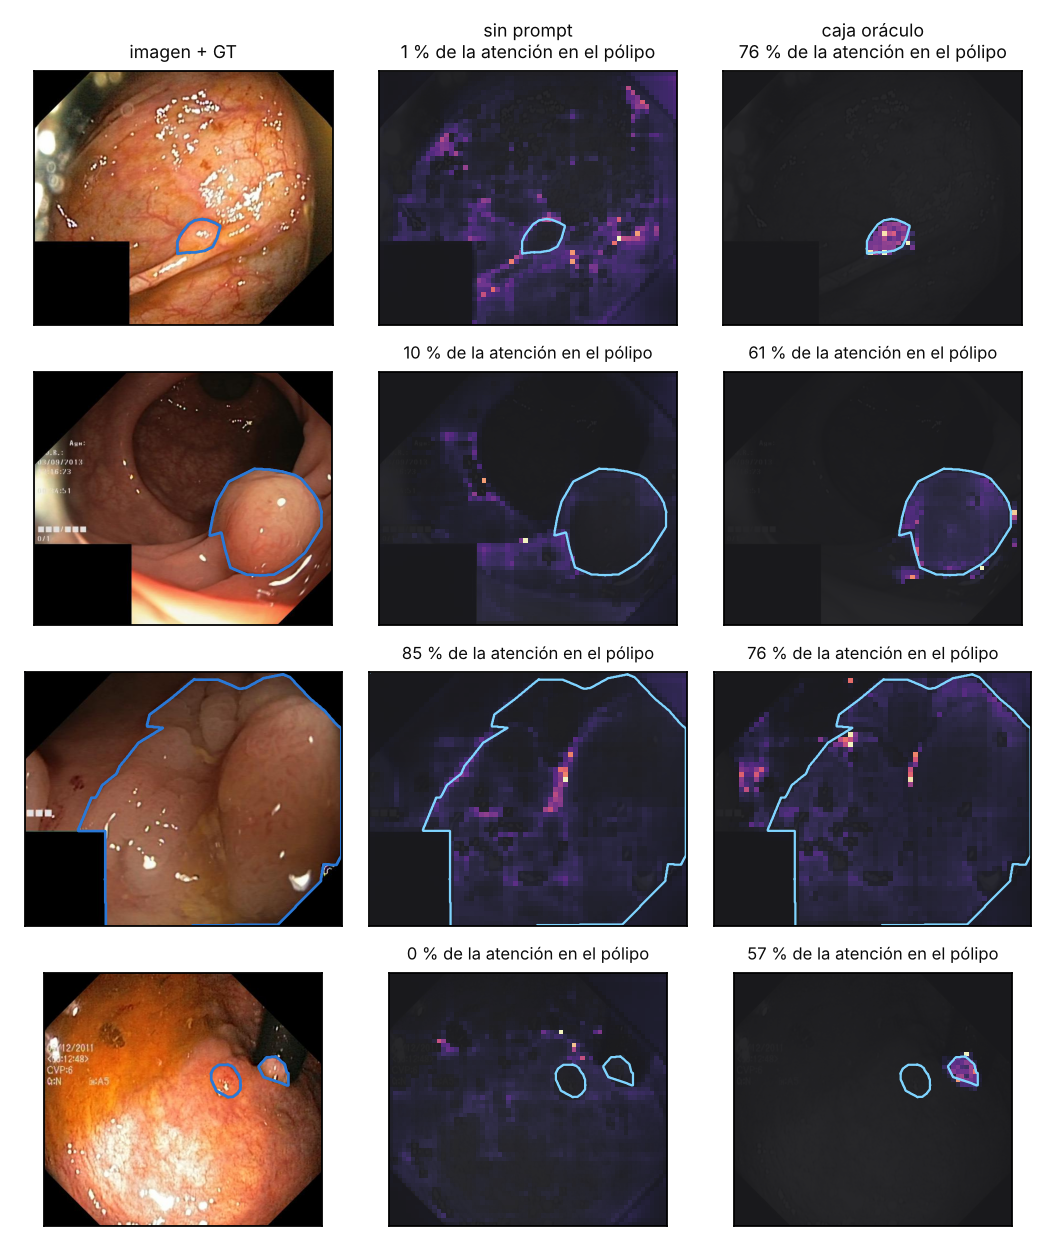

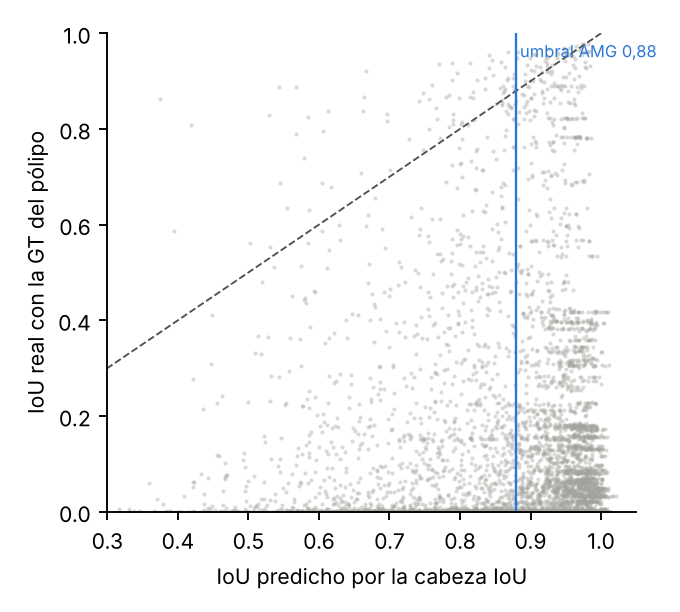

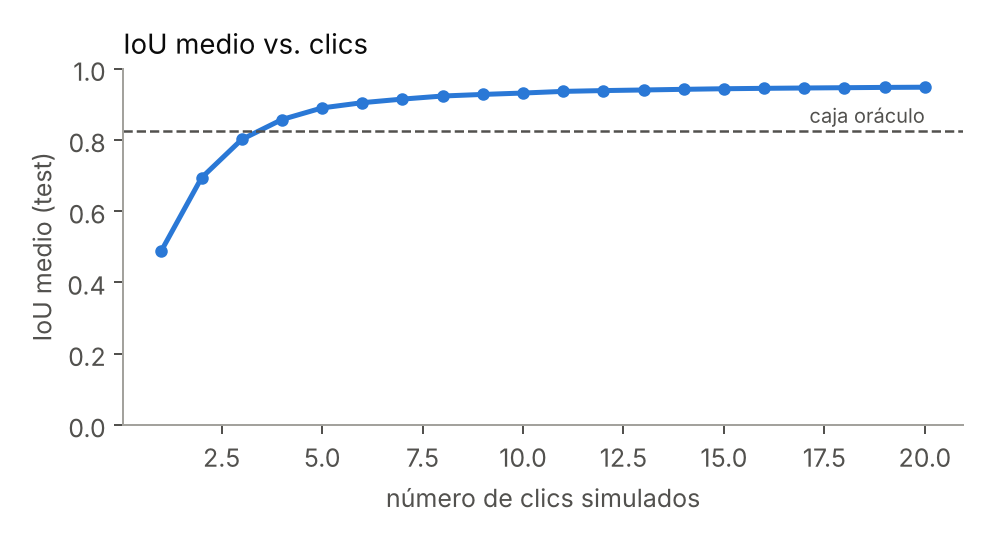

In [6]:
for f in ['sin_prompt_ejemplos.png', 'atencion_decoder.png', 'calibracion_amg.png', 'iou_vs_clics.png']:
    if (F / f).exists():
        display(Image(F / f, width=650))

## Intervención: tokens aprendidos

{
 "k1_meanpoint": {
  "test_dice_per_seed": [
   0.27797174765525345,
   0.27670061060192397,
   0.28088644376332184
  ],
  "mean": 0.27851960067349973,
  "std": 0.0021460212046868735,
  "n_params": 256,
  "best_epoch": [
   6,
   5,
   3
  ]
 },
 "k4_meanpoint": {
  "test_dice_per_seed": [
   0.3254782622056218,
   0.30198820080022987,
   0.3259504557062952
  ],
  "mean": 0.31780563957071567,
  "std": 0.013700338266592883,
  "n_params": 1024,
  "best_epoch": [
   6,
   2,
   3
  ]
 },
 "k4_random": {
  "test_dice_per_seed": [
   0.008153673369729685
  ],
  "mean": 0.008153673369729685,
  "std": 0.0,
  "n_params": 1024,
  "best_epoch": [
   1
  ]
 }
}


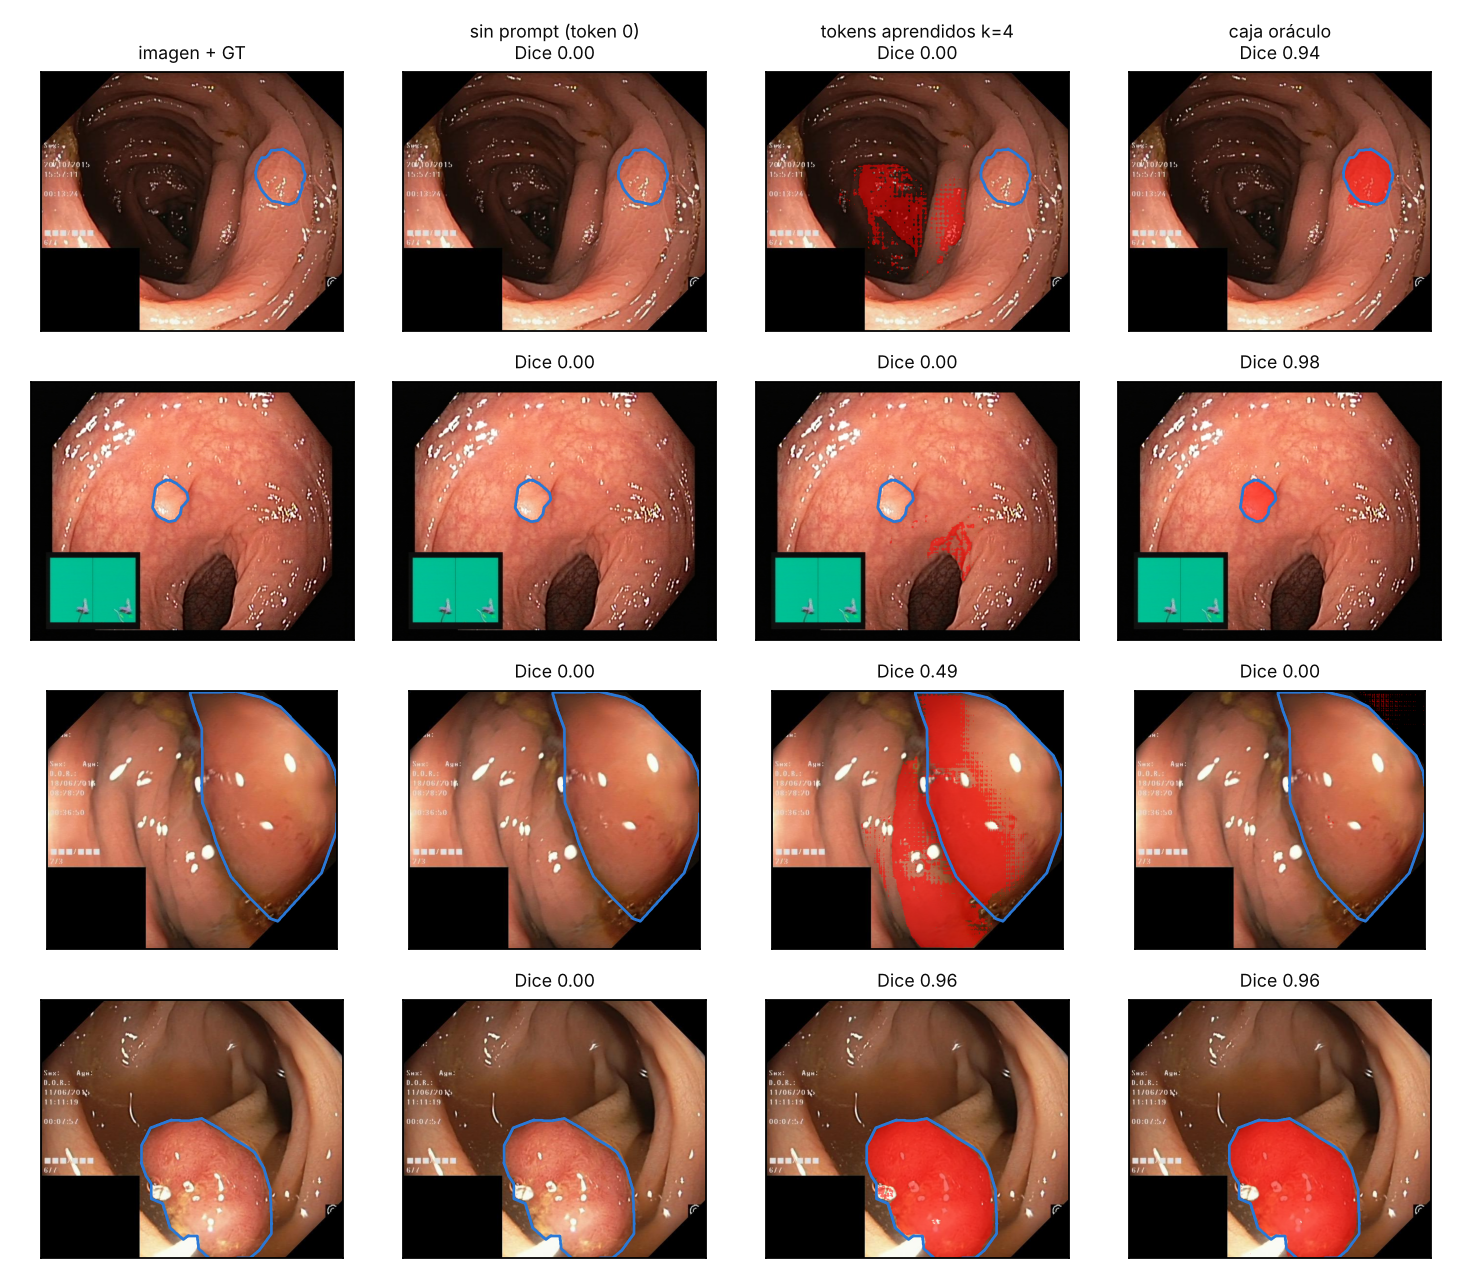

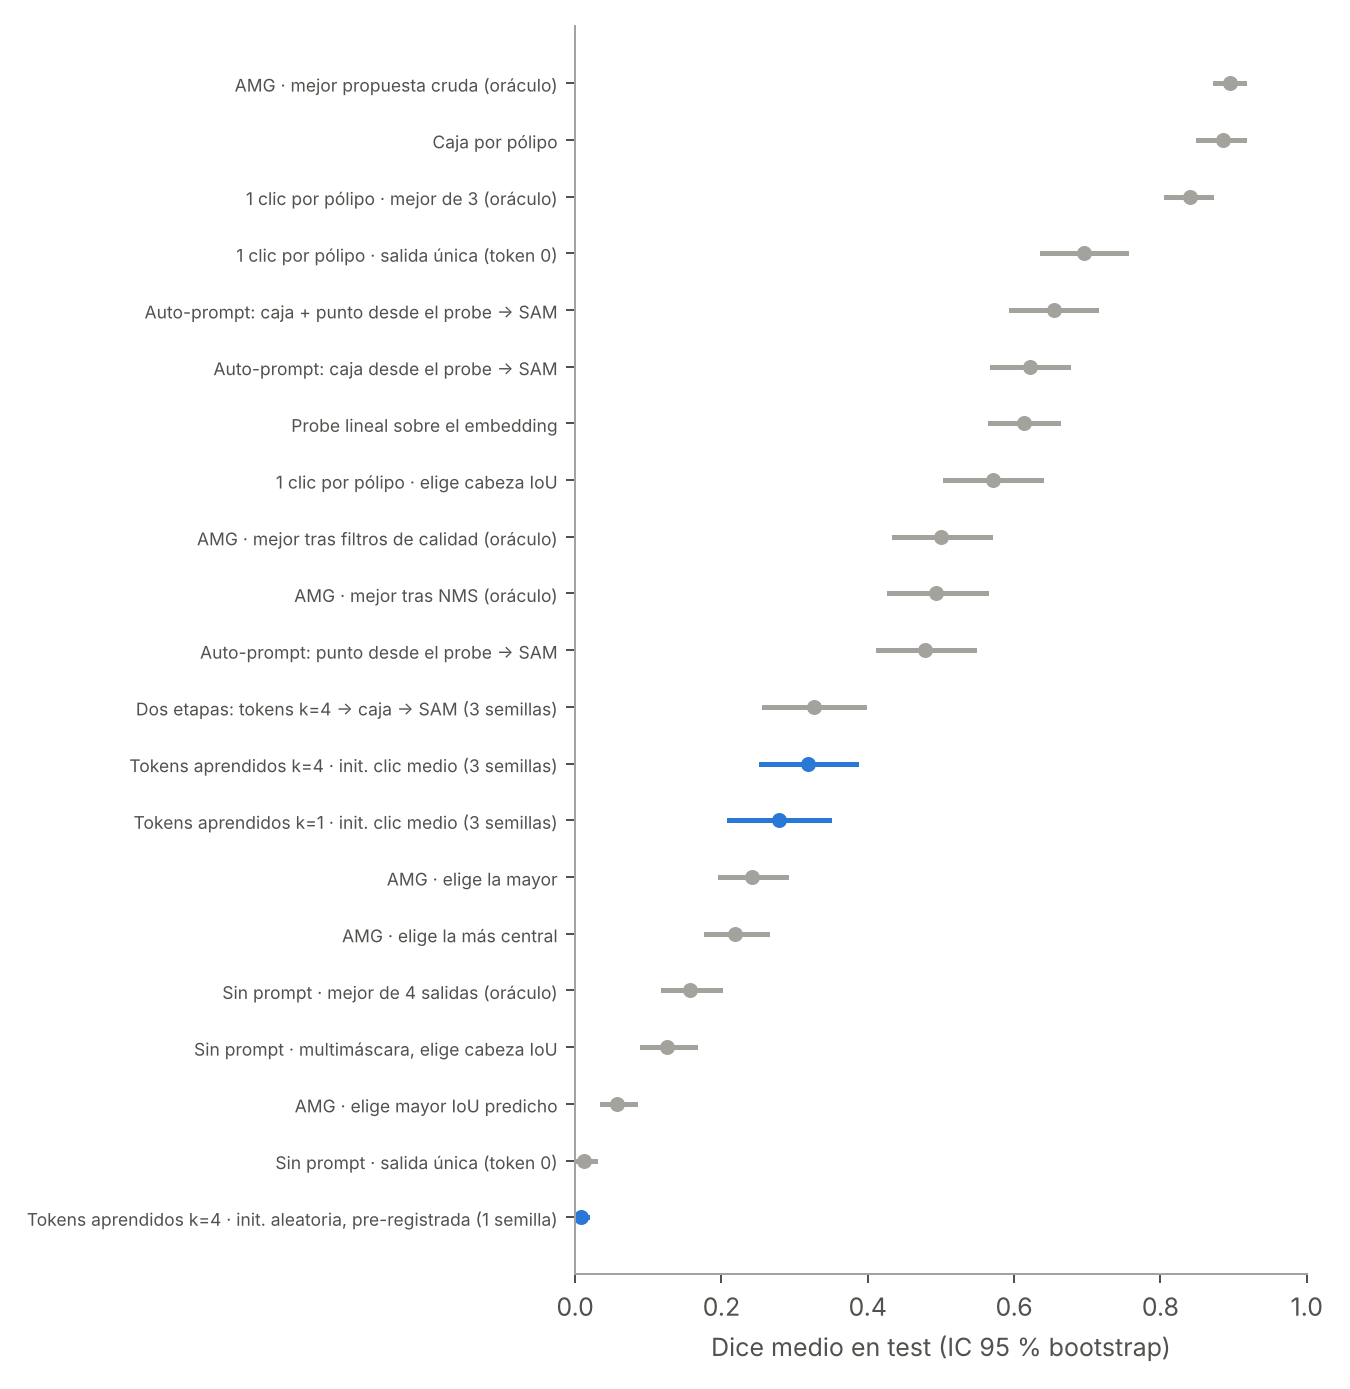

In [7]:
print(json.dumps({k: {kk: v[kk] for kk in ['test_dice_per_seed', 'mean', 'std', 'n_params', 'best_epoch']} for k, v in S.get('learned', {}).items()}, indent=1))
for f in ['cualitativo_tokens.png', 'comparacion_metodos.png']:
    if (F / f).exists():
        display(Image(F / f, width=650))

## Pruebas pareadas (Wilcoxon) y fracción de la brecha recuperada

In [8]:
pd.DataFrame(S['paired_tests']).T

,mean_diff,ci95,wilcoxon_p
Tokens aprendidos k=1 · init. clic medio (3 semillas) vs Probe lineal sobre el embedding,-0.335659,"[-0.4056834876177975, -0.26562523093758034]",0.0
Tokens aprendidos k=1 · init. clic medio (3 semillas) vs Auto-prompt: caja desde el probe → SAM,-0.343897,"[-0.4163157989482256, -0.2707604837386928]",0.0
Tokens aprendidos k=1 · init. clic medio (3 semillas) vs Caja por pólipo,-0.607375,"[-0.6780560038190145, -0.534877661506401]",0.0
Tokens aprendidos k=1 · init. clic medio (3 semillas) vs Sin prompt · salida única (token 0),0.266335,"[0.1984708856641354, 0.3360361994958276]",0.0
Tokens aprendidos k=4 · init. clic medio (3 semillas) vs Probe lineal sobre el embedding,-0.296373,"[-0.3634508818473434, -0.2289967444384994]",0.0
Tokens aprendidos k=4 · init. clic medio (3 semillas) vs Auto-prompt: caja desde el probe → SAM,-0.304611,"[-0.3752181640841323, -0.23466759944820156]",0.0
Tokens aprendidos k=4 · init. clic medio (3 semillas) vs Caja por pólipo,-0.568089,"[-0.6382695101142141, -0.49793490206195645]",0.0
Tokens aprendidos k=4 · init. clic medio (3 semillas) vs Sin prompt · salida única (token 0),0.305622,"[0.24007931841284866, 0.37385214117304416]",0.0
"Tokens aprendidos k=4 · init. aleatoria, pre-registrada (1 semilla) vs Probe lineal sobre el embedding",-0.606025,"[-0.6536644199805909, -0.557863815694141]",0.0
"Tokens aprendidos k=4 · init. aleatoria, pre-registrada (1 semilla) vs Auto-prompt: caja desde el probe → SAM",-0.614263,"[-0.6661211637328696, -0.5610790332208352]",0.0


In [9]:
pd.Series(S['gap_recovered']).sort_values()

Tokens aprendidos k=4 · init. aleatoria, pre-registrada (1 semilla)   -0.004613
Sin prompt · salida única (token 0)                                    0.000000
AMG · elige mayor IoU predicho                                         0.052226
Sin prompt · multimáscara, elige cabeza IoU                            0.130186
Sin prompt · mejor de 4 salidas (oráculo)                              0.166127
AMG · elige la más central                                             0.236087
AMG · elige la mayor                                                   0.262318
Tokens aprendidos k=1 · init. clic medio (3 semillas)                  0.304833
Tokens aprendidos k=4 · init. clic medio (3 semillas)                  0.349797
Dos etapas: tokens k=4 → caja → SAM (3 semillas)                       0.359701
Auto-prompt: punto desde el probe → SAM                                0.533772
AMG · mejor tras NMS (oráculo)                                         0.550425
AMG · mejor tras filtros de calidad (orá